# __Competición CNN 2026. Clasificación multiclase.__

Para esta segunda parte de la competición hemos decidido clasificar las imágenes del mismo dataset de cartas según su palo: tréboles, diamantes, corazones y picas. El joker no tiene palo y, como el enunciado prohíbe eliminar imágenes de cualquier partición, lo mantenemos como una quinta clase propia. El problema tiene por tanto 5 clases.

Elegimos el palo porque no es una solución trivial. El color separa fácilmente rojos (corazones y diamantes) de negros (tréboles y picas), pero distinguir dentro de cada pareja obliga a la red a fijarse en la forma de los símbolos, que además son pequeños y aparecen en posiciones y tamaños distintos según el valor de la carta. Es una tarea multiclase de verdad, no una variante del problema binario.

Hemos decidido hacer esta clasificación con multiclase porque cada carta tiene exactamente un palo, asi que son excluyentes. Con un softmax con una sola salida, podemos modelar esto justo.

## Instalación de librerías.

En este primer bloque se importan las librerías necesarias para trabajar en PyTorch, además del cálculo de métricas de evaluación. También se definen las rutas de los directorios y se fijan las semillas aleatorias.

Igual que en la parte binaria, los hiperparámetros que más se tocan (tamaño de imagen, batch size, épocas y paciencia del early stopping) quedan como constantes al principio. La semilla vuelve a ser 73. El destino de la reorganización es una carpeta distinta a la de la parte binaria para no pisar nada de lo anterior.

Para el entrenamiento del modelo se usará la GPU ya que es más rápida para estos procesos.

In [ ]:
import os
import shutil
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, TensorDataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

ORIGEN_DIR = "cards"
DESTINO_DIR = "cards_reorganizado_palos"

IMG_SIZE = 224 # Tamaño de la imagen para el modelo
BATCH_SIZE = 32 # Tamaño del lote para el entrenamiento
EPOCHS = 80
PATIENCE = 13 # Número de épocas sin mejora para detener el entrenamiento
SEED = 73

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): # En caso de que haya GPU disponible, se fija la semilla para reproducibilidad
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Si hay GPU disponible, se utiliza; de lo contrario, se utiliza la CPU
print(f"Dispositivo activo: {device}")

Dispositivo activo: cuda


### Descargar datasets. (Opcional)

En el caso de tener un token de kaggle configurado se puede descargar mediante los siguientes comandos de bash:

- kaggle datasets download -d cesarvidal/cards-dataset
- unzip -q cards-dataset.zip -d cards

## Reorganización del conjunto de datos para clasificación multiclase

A partir del dataset original, dividido en 53 carpetas por tipo de carta, se genera una nueva estructura con una carpeta por palo dentro de cada partición (train, valid y test). Las clases son clubs, diamonds, hearts, spades y joker. Vamos a copiar las imagenes a otra carpeta llamada cards_reorganizado_palos sin tocar la carpeta cards.

El palo se obtiene del nombre de la carpeta original, por ejemplo "ace of spades" al tener "spades" en el nombre, almacenaremos la imagen en la carpeta "spades". Si alguna carpeta no encaja en ninguna clase, el código lanza un error en lugar de ignorarla en silencio, ya que no podemos perder imágenes.

Seguimos la filosofía que usamos en la parte binaria.

In [18]:
CLASES = ["clubs", "diamonds", "hearts", "spades", "joker"]
NUM_CLASSES = len(CLASES)
CLASE_A_IDX = {c: i for i, c in enumerate(CLASES)}

def clase_de_carpeta(nombre):
    nombre = nombre.lower() # en caso de tener mayusculas, se pasa a minúsculas
    for palo in ["clubs", "diamonds", "hearts", "spades"]:
        if palo in nombre:
            return palo
    if "joker" in nombre: # Podria dar problema si hay un joker que se llame "joker of hearts", pero no es el caso en este dataset
        return "joker"
    raise ValueError(f"Carpeta sin clase asignada: {nombre}")

# Si no existe la carpeta cards_reorganizado_palos, la crea
if not os.path.exists(DESTINO_DIR):
    for split in ["train", "valid", "test"]:
        for clase in CLASES:
            os.makedirs(os.path.join(DESTINO_DIR, split, clase), exist_ok=True) # Creamos las subcarpetas para cada clase dentro de cada split (train, valid, test)

        split_path = os.path.join(ORIGEN_DIR, split) # Ruta de la carpeta de origen (train, valid, test)
        for carpeta_carta in os.listdir(split_path):
            carta_path = os.path.join(split_path, carpeta_carta)
            if os.path.isdir(carta_path):
                clase_destino = clase_de_carpeta(carpeta_carta)

                for archivo in os.listdir(carta_path):
                    if archivo.lower().endswith(".jpg"):
                        origen_img = os.path.join(carta_path, archivo)
                        nuevo_nombre = f"{carpeta_carta.replace(' ', '_')}_{archivo}"
                        destino_img = os.path.join(DESTINO_DIR, split, clase_destino, nuevo_nombre)
                        shutil.copy2(origen_img, destino_img)

TRAIN_DIR = os.path.join(DESTINO_DIR, "train")
VALID_DIR = os.path.join(DESTINO_DIR, "valid")
TEST_DIR  = os.path.join(DESTINO_DIR, "test")

### Carga y redimensionamiento de las imágenes

Se leen las imágenes de cada partición, se redimensionan a 224 x 224 píxeles y se almacenan con su etiqueta, que ahora es un entero entre 0 y 4 (los 4 palos + el joker) según el orden de CLASES. Se mantiene la comprobación de archivos corruptos: si cv2.imread devuelve None, la imagen se omite y más abajo comprobaremos que los números de cartas no varien lo que significaría que hemos perdido alguna carta a la hora de redimensionar u organizar.

In [4]:
def load_dataset(base_dir):
    images = []
    labels = []

    for class_name, label in CLASE_A_IDX.items():
        class_dir = os.path.join(base_dir, class_name)
        for filename in os.listdir(class_dir):
            if filename.lower().endswith(".jpg"):
                img_path = os.path.join(class_dir, filename)
                img = cv2.imread(img_path)
                if img is not None:
                    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                    images.append(img)
                    labels.append(label)

    return np.array(images), np.array(labels)

X_train, y_train = load_dataset(TRAIN_DIR)
X_val, y_val     = load_dataset(VALID_DIR)
X_test, y_test   = load_dataset(TEST_DIR)

print(f"Train: {X_train.shape}, Valid: {X_val.shape}, Test: {X_test.shape}")

Train: (7619, 224, 224, 3), Valid: (265, 224, 224, 3), Test: (265, 224, 224, 3)


### Observar algún dato.

Se seleccionan 8 imágenes aleatorias del conjunto de entrenamiento y se muestran con su clase. Sirve para comprobar que las etiquetas tienen sentido (un as de picas no puede aparecer como corazones) y que los colores son correctos, ya que OpenCV carga en BGR y hay que convertir a RGB para pintar. Aquí es especialmente importante, porque el color es una pista fuerte para el palo.

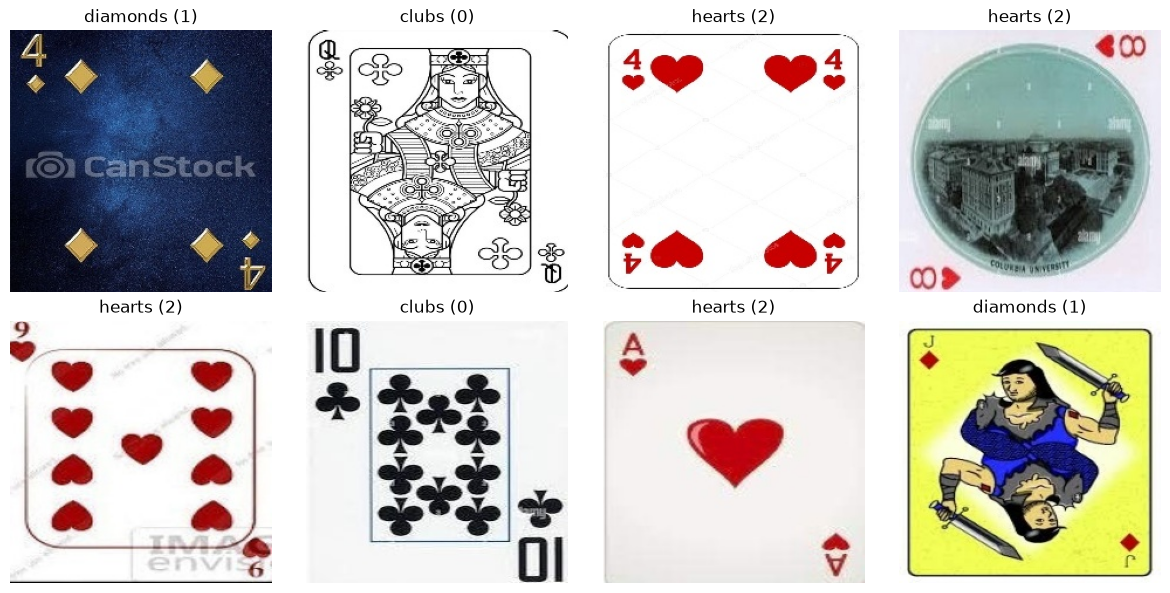

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
indices = random.sample(range(len(X_train)), 8)

for ax, idx in zip(axes.flat, indices):
    img_rgb = cv2.cvtColor(X_train[idx], cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_title(f"{CLASES[y_train[idx]]} ({y_train[idx]})")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Análisis del dataset

Antes de preprocesar queremos saber si el dataset está equilibrado. En el original hay 13 valores por palo y un único tipo de comodín, así que se espera que las cuatro clases de palo sean parecidas entre sí y que los jokers tengan bastantes menos imágenes. Primero se muestra el conteo por tipo de carta original, coloreado por la clase de palo a la que pertenece.

train: mínimo 108, máximo 181, media 143.8 imágenes por tipo
valid: mínimo 5, máximo 5, media 5.0 imágenes por tipo
test: mínimo 5, máximo 5, media 5.0 imágenes por tipo


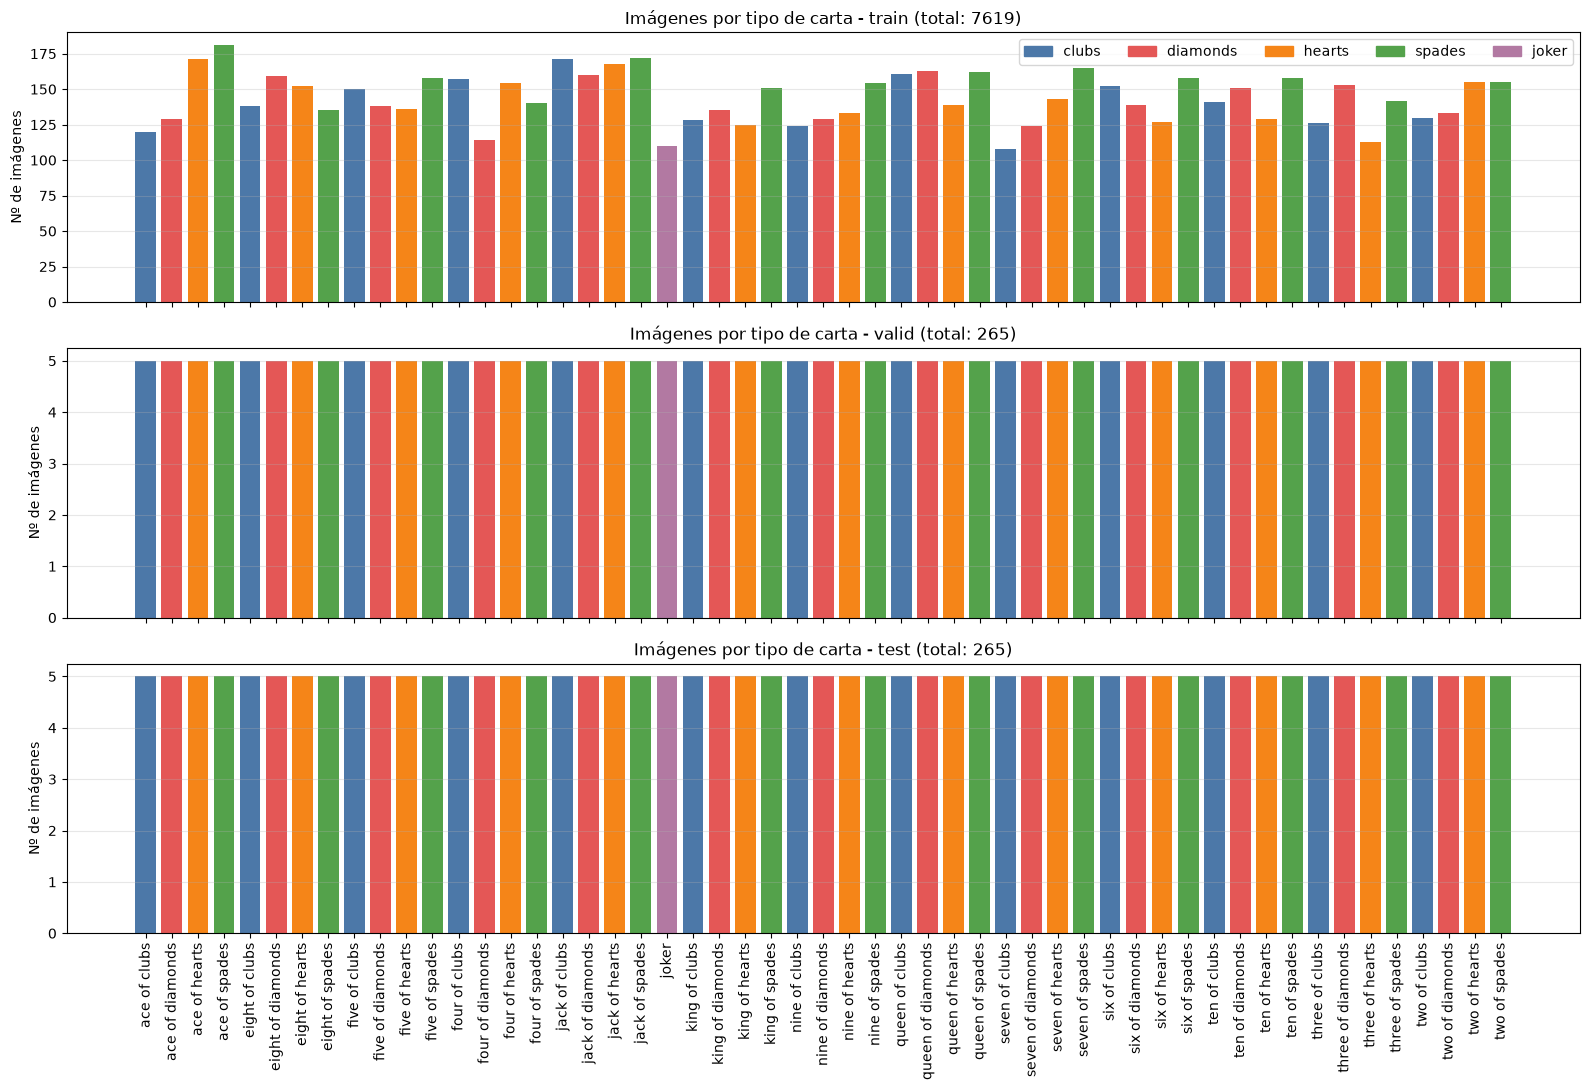

In [ ]:
PALETA = {"clubs": "#4C78A8", "diamonds": "#E45756", "hearts": "#F58518", "spades": "#54A24B", "joker": "#B279A2"} # Colores sacados de internet.

def contar_por_tipo(split): # Funcion para contar el número de imágenes por tipo de carta en cada split (train, valid, test)
    base = os.path.join(ORIGEN_DIR, split) 
    conteo = {}
    for carpeta in sorted(os.listdir(base)):
        ruta = os.path.join(base, carpeta)
        if os.path.isdir(ruta):
            conteo[carpeta] = len(os.listdir(ruta))
    return conteo

conteos = {s: contar_por_tipo(s) for s in ["train", "valid", "test"]} 
tipos = sorted(conteos["train"].keys())
colores = [PALETA[clase_de_carpeta(t)] for t in tipos] 

from matplotlib.patches import Patch # Formato de grafica recogido de stackoverflow.
fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)
for ax, split in zip(axes, ["train", "valid", "test"]):
    valores = [conteos[split].get(t, 0) for t in tipos]
    ax.bar(range(len(tipos)), valores, color=colores)
    ax.set_title(f"Imágenes por tipo de carta - {split} (total: {sum(valores)})")
    ax.set_ylabel("Nº de imágenes")
    ax.grid(axis="y", alpha=0.3)
    print(f"{split}: mínimo {min(valores)}, máximo {max(valores)}, media {np.mean(valores):.1f} imágenes por tipo")

axes[-1].set_xticks(range(len(tipos)))
axes[-1].set_xticklabels(tipos, rotation=90)
axes[0].legend(handles=[Patch(color=PALETA[c], label=c) for c in CLASES], ncol=5)
plt.tight_layout()
plt.savefig("imagenes_por_tipo_palos.png", dpi=300)
plt.show()

Comprobamos también que no se nos haya quedado ninguna imagen sin cargar, porque el enunciado no permite eliminar ninguna de ninguna partición. Se comparan las imágenes en disco con las que carga load_dataset y, si hay diferencia, se muestran los archivos afectados. Esto es a lo que haciamos referencia en un apartado superior. Con esta gráfica podemos ver la distribución de cantidad de imágenes de cada tipo en las diferentes subcarpetas train, test y valid. Observamos que los palos estan mas o menos equilibrados con una clara diferencia en los jokers teniendo aproximadamente un 1.5% de participación. Esto nos va a obligar a usar pesos por clase.

In [7]:
cargadas = {"train": len(X_train), "valid": len(X_val), "test": len(X_test)}

def archivos_no_cargados(split):
    base = os.path.join(ORIGEN_DIR, split)
    problemas = []
    for carpeta in os.listdir(base):
        ruta = os.path.join(base, carpeta)
        if not os.path.isdir(ruta):
            continue
        for archivo in os.listdir(ruta):
            ruta_img = os.path.join(ruta, archivo)
            if not archivo.lower().endswith(".jpg") or cv2.imread(ruta_img) is None:
                problemas.append(ruta_img)
    return problemas

for split in ["train", "valid", "test"]:
    en_disco = sum(conteos[split].values())
    print(f"{split}: {en_disco} en disco, {cargadas[split]} cargadas, diferencia: {en_disco - cargadas[split]}")
    if en_disco != cargadas[split]:
        for ruta_img in archivos_no_cargados(split):
            print("   no cargada:", ruta_img)

train: 7619 en disco, 7619 cargadas, diferencia: 0
valid: 265 en disco, 265 cargadas, diferencia: 0
test: 265 en disco, 265 cargadas, diferencia: 0


Una vez comprobado que no hemos perdido imagenes por el camino, pasamos al reparto con las cinco clases del problema, por partición. Con esto se ve el desbalanceo que se compensa con pesos por clase en la función de pérdida. Esto es dado a que hay menos imagenes de unos palos frente a otros, siendo los jokers los que menos imagenes tienen y las espadas las que mas.

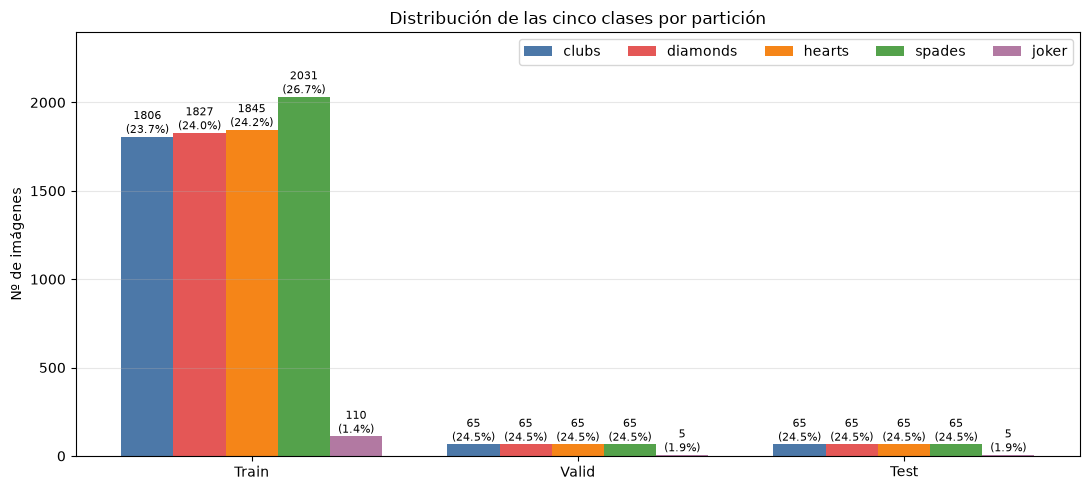

clubs: train 1806, valid 65, test 65
diamonds: train 1827, valid 65, test 65
hearts: train 1845, valid 65, test 65
spades: train 2031, valid 65, test 65
joker: train 110, valid 5, test 5


In [8]:
nombres_split = ["Train", "Valid", "Test"]
conteo_clases = np.array([[int((y == c).sum()) for c in range(NUM_CLASSES)] for y in (y_train, y_val, y_test)])

x = np.arange(len(nombres_split))
ancho = 0.16
fig, ax = plt.subplots(figsize=(11, 5))
for c, nombre in enumerate(CLASES):
    barras = ax.bar(x + (c - (NUM_CLASSES - 1) / 2) * ancho, conteo_clases[:, c], ancho, label=nombre, color=PALETA[nombre])
    for barra, n, total in zip(barras, conteo_clases[:, c], conteo_clases.sum(axis=1)):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                f"{n}\n({100 * n / total:.1f}%)", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(nombres_split)
ax.set_ylabel("Nº de imágenes")
ax.set_title("Distribución de las cinco clases por partición")
ax.set_ylim(0, conteo_clases.max() * 1.18)
ax.legend(ncol=5)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("distribucion_clases_palos.png", dpi=300)
plt.show()

for c, nombre in enumerate(CLASES):
    print(f"{nombre}: train {conteo_clases[0, c]}, valid {conteo_clases[1, c]}, test {conteo_clases[2, c]}")

**Data augmentation.** Rotación de 5 grados y cambios suaves de brillo, contraste y saturación, solo en train. No usamos cambio de tono porque el color distingue rojo de negro.

## Preprocesamiento, Data Augmentation y creación de DataLoaders

Se pasan las imágenes de BGR a RGB, se normalizan a [0, 1] y se reordenan las dimensiones a N, Canales, Alto, Ancho. Las etiquetas pasan a ser enteros de tipo long con forma (N,), que es la entrada que espera CrossEntropyLoss.

El data augmentation se aplica solo a entrenamiento y mantiene la filosofía de la parte binaria: rotación de hasta 5 grados y cambios suaves de brillo, contraste y saturación. No se usa cambio de tono (hue), porque el rojo y el negro son lo que separa los palos en dos grupos y alterar el tono podría confundir la señal. Tampoco hay volteos verticales ni rotaciones grandes, ya que no esperamos ver cartas del revés en test. Validación y test van sin transformaciones.

Los DataLoaders usan lotes de 32 imágenes y solo el de entrenamiento mezcla los datos en cada época.

In [9]:
def preparar_tensores(X, y):
    X_rgb = X[:, :, :, ::-1].copy()
    X_tensor = torch.tensor(X_rgb, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    y_tensor = torch.tensor(y, dtype=torch.long)
    return X_tensor, y_tensor

X_train_t, y_train_t = preparar_tensores(X_train, y_train)
X_val_t, y_val_t     = preparar_tensores(X_val, y_val)
X_test_t, y_test_t   = preparar_tensores(X_test, y_test)

train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
])

class AugmentedDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        img = self.X[idx]
        if self.transform:
            img = self.transform(img)
        return img, self.y[idx]

train_loader = DataLoader(AugmentedDataset(X_train_t, y_train_t, transform=train_transform), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

## Definición de la CNN

Se reutiliza la arquitectura de la parte binaria: cinco bloques convolucionales con dos Conv2d cada uno, BatchNorm2d, LeakyReLU, MaxPool2d y Dropout, con filtros 16, 32, 64, 128 y 256 y la imagen reduciéndose de 224 x 224 a 7 x 7. La primera convolución usa kernel 5 x 5 y el resto 3 x 3.

La única modificación estructural es la última capa, que pasa de una neurona a NUM_CLASSES = 5 neuronas.

In [10]:
def bloque(c_in, c_out, k=3, p_drop=0.1):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=k, padding=k // 2),
        nn.BatchNorm2d(c_out),
        nn.LeakyReLU(0.1),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.LeakyReLU(0.1),
        nn.MaxPool2d(2, 2),
        nn.Dropout(p_drop),
    )

class CardsCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super(CardsCNN, self).__init__()
        self.features = nn.Sequential(
            bloque(3, 16, k=5),   # 224 a 112
            bloque(16, 32),       # 112 a 56
            bloque(32, 64),       # 56 a 28
            bloque(64, 128),      # 28 a 14
            bloque(128, 256),     # 14 a 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = CardsCNN().to(device)
print(model)

CardsCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.1)
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): LeakyReLU(negative_slope=0.1)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.1)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, a

## Configuración y aprendizaje

La función de pérdida es CrossEntropyLoss con un peso por clase para compensar que el comodín tiene muchas menos imágenes que cada palo. El peso de la clase c es la raíz de N / (C · n_c), donde N es el total de imágenes de entrenamiento, C el número de clases y n_c las imágenes de la clase c. La raíz suaviza el peso, igual que hicimos en la parte binaria, para no penalizar en exceso los errores de la clase minoritaria. El optimizador es Adam (learning rate 0.001, weight_decay 1e-4).

El bucle es el de la parte binaria: scheduler ReduceLROnPlateau sobre la pérdida de validación (factor 0.5, paciencia 4), early stopping con paciencia 13 sobre la pérdida de validación y guardado del mejor modelo según F1 de validación, desempatando por menor pérdida. La diferencia es que el F1 es ahora *macro*: la media de los F1 de cada clase, de modo que el comodín pesa igual que cada palo y un mal resultado en él no queda oculto por las clases grandes.

Las métricas de entrenamiento las hemos calculado tanto con dropout activo comocon data augmentation, y las de validación. Esto puede ser que el F1 de train puede quedar por debajo del de validación sin que haya ningún fallo.

In [11]:
conteo_train = np.bincount(y_train, minlength=NUM_CLASSES)
pesos_clase = (len(y_train) / (NUM_CLASSES * conteo_train)) ** 0.5
print("Pesos por clase:", dict(zip(CLASES, np.round(pesos_clase, 3))))

criterion = nn.CrossEntropyLoss(weight=torch.tensor(pesos_clase, dtype=torch.float32).to(device))
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4)

best_val_f1 = 0.0
best_val_loss_ckpt = float("inf")
best_val_loss = float("inf")
epochs_sin_mejora = 0
MODEL_PATH = "modelo_cnn_cartas_palos.pth"
history = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": []}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    train_preds, train_targets = [], []

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        train_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        train_targets.extend(labels.cpu().numpy())

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_f1 = f1_score(train_targets, train_preds, average="macro")

    model.eval()
    val_running_loss = 0.0
    val_preds, val_targets = [], []

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * inputs.size(0)
            val_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    epoch_val_loss = val_running_loss / len(val_loader.dataset)
    epoch_val_f1 = f1_score(val_targets, val_preds, average="macro")

    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["train_f1"].append(epoch_train_f1)
    history["val_f1"].append(epoch_val_f1)

    print(f"Época [{epoch+1:02d}/{EPOCHS:02d}] | Train Loss: {epoch_train_loss:.4f} - F1: {epoch_train_f1:.4f} | Val Loss: {epoch_val_loss:.4f} - F1: {epoch_val_f1:.4f} | LR: {optimizer.param_groups[0]['lr']:.6f}")

    scheduler.step(epoch_val_loss)

    if (epoch_val_f1 > best_val_f1) or (epoch_val_f1 == best_val_f1 and epoch_val_loss < best_val_loss_ckpt):
        best_val_f1 = epoch_val_f1
        best_val_loss_ckpt = epoch_val_loss
        torch.save(model.state_dict(), MODEL_PATH)

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        epochs_sin_mejora = 0
    else:
        epochs_sin_mejora += 1
        if epochs_sin_mejora >= PATIENCE:
            print(f"Early stopping en la época {epoch+1}")
            break

Pesos por clase: {'clubs': np.float64(0.919), 'diamonds': np.float64(0.913), 'hearts': np.float64(0.909), 'spades': np.float64(0.866), 'joker': np.float64(3.722)}
Época [01/80] | Train Loss: 2.0455 - F1: 0.2988 | Val Loss: 1.1122 - F1: 0.3877 | LR: 0.001000
Época [02/80] | Train Loss: 1.0337 - F1: 0.4715 | Val Loss: 0.7105 - F1: 0.5259 | LR: 0.001000
Época [03/80] | Train Loss: 0.7760 - F1: 0.5865 | Val Loss: 0.6631 - F1: 0.5676 | LR: 0.001000
Época [04/80] | Train Loss: 0.6288 - F1: 0.6716 | Val Loss: 0.5544 - F1: 0.7410 | LR: 0.001000
Época [05/80] | Train Loss: 0.4565 - F1: 0.7784 | Val Loss: 0.2420 - F1: 0.8552 | LR: 0.001000
Época [06/80] | Train Loss: 0.3585 - F1: 0.8362 | Val Loss: 0.1869 - F1: 0.8242 | LR: 0.001000
Época [07/80] | Train Loss: 0.3008 - F1: 0.8620 | Val Loss: 0.2653 - F1: 0.8425 | LR: 0.001000
Época [08/80] | Train Loss: 0.3350 - F1: 0.8404 | Val Loss: 0.1450 - F1: 0.9202 | LR: 0.001000
Época [09/80] | Train Loss: 0.2865 - F1: 0.8785 | Val Loss: 0.1850 - F1: 0.90

Vemos que hace un Early Stopping en la Época 40 y que el mejor modelo entrenado es el de la epoca 27 con un F1 de validación de 1,0000 y una pérdida de 0,0060. El modelo es el 27 por la paciencia que hemos declarado al principio: 
27 + 13 = 40. 
Mejor modelo + Paciencia = Epoca de early stopping.

## Visualización de las curvas de aprendizaje

Se representan la pérdida y el F1 macro de entrenamiento y validación a lo largo de las épocas, para analizar la convergencia y detectar sobreajuste. El eje de épocas se adapta a las que se hayan ejecutado realmente por el early stopping.

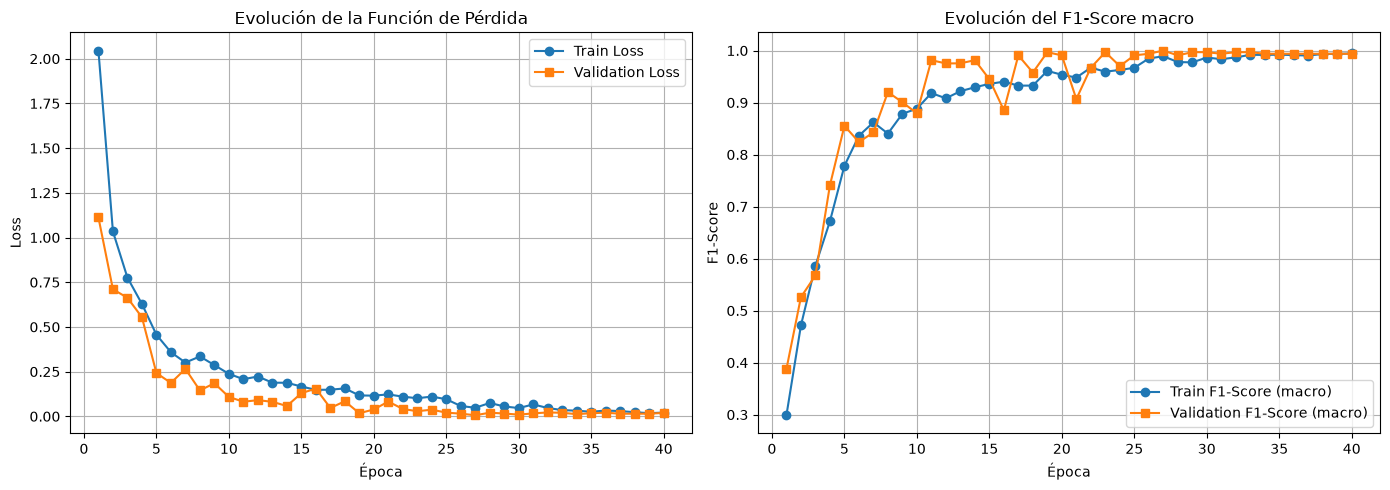

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epocas = range(1, len(history["train_loss"]) + 1)
axes[0].plot(epocas, history["train_loss"], label="Train Loss", marker="o")
axes[0].plot(epocas, history["val_loss"], label="Validation Loss", marker="s")
axes[0].set_title("Evolución de la Función de Pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epocas, history["train_f1"], label="Train F1-Score (macro)", marker="o")
axes[1].plot(epocas, history["val_f1"], label="Validation F1-Score (macro)", marker="s")
axes[1].set_title("Evolución del F1-Score macro")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("F1-Score")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("graficas_entrenamiento_palos.png", dpi=300)
plt.show()

**Curvas de aprendizaje.** Las pérdidas de train y validación convergen sin separarse, así que no hay sobreajuste. La validación va por debajo de train porque train se mide con dropout y augmentation. El F1 de validación oscila hasta la época 25 y se estabiliza cuando el scheduler baja el learning rate.

## Evaluación final

Se cargan los mejores pesos guardados y se evalúa sobre test, que solo se usa en este punto. Se calculan F1, precisión y exhaustividad con promedio macro, la accuracy y el informe por clase.

Para el desempate de la competición se calculan las tasas de falsos positivos y falsos negativos. Con más de dos clases se obtienen en modo uno contra todos: para la clase c, FP son las imágenes que el modelo predice como c sin serlo y FN las imágenes de c que predice como otra. Se muestran por clase y su media. La matriz de confusión es de 5 x 5, en valores absolutos y normalizada por filas (cada fila suma 1, de modo que la diagonal es la exhaustividad de cada clase).

F1-Score macro Test:  0.9969
Precision macro Test: 0.9970
Recall macro Test:    0.9969
Accuracy Test:        0.9962

clubs     | FP: 0 (tasa 0.0000) | FN: 0 (tasa 0.0000)
diamonds  | FP: 0 (tasa 0.0000) | FN: 1 (tasa 0.0154)
hearts    | FP: 0 (tasa 0.0000) | FN: 0 (tasa 0.0000)
spades    | FP: 1 (tasa 0.0050) | FN: 0 (tasa 0.0000)
joker     | FP: 0 (tasa 0.0000) | FN: 0 (tasa 0.0000)
Tasa FP media: 0.0010 | Tasa FN media: 0.0031

              precision    recall  f1-score   support

       clubs     1.0000    1.0000    1.0000        65
    diamonds     1.0000    0.9846    0.9922        65
      hearts     1.0000    1.0000    1.0000        65
      spades     0.9848    1.0000    0.9924        65
       joker     1.0000    1.0000    1.0000         5

    accuracy                         0.9962       265
   macro avg     0.9970    0.9969    0.9969       265
weighted avg     0.9963    0.9962    0.9962       265



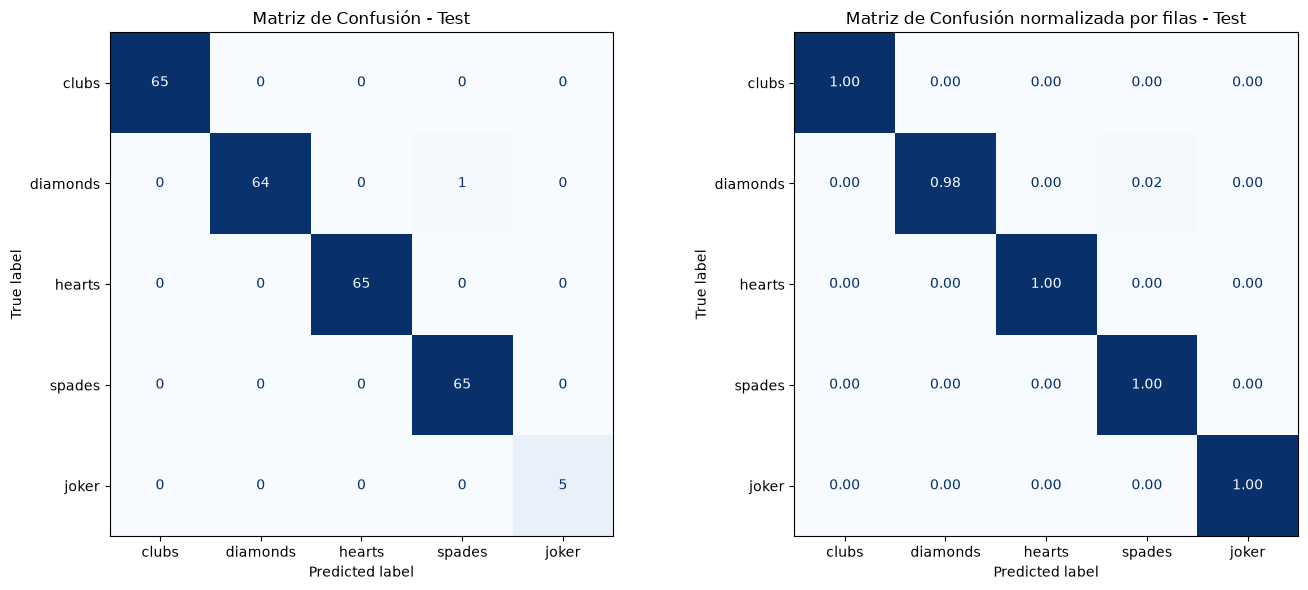

In [13]:
model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
model.eval()

test_preds, test_targets = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs.to(device))
        test_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        test_targets.extend(labels.numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)

test_f1 = f1_score(test_targets, test_preds, average="macro")
test_precision = precision_score(test_targets, test_preds, average="macro", zero_division=0)
test_recall = recall_score(test_targets, test_preds, average="macro", zero_division=0)
test_acc = accuracy_score(test_targets, test_preds)

cm = confusion_matrix(test_targets, test_preds, labels=range(NUM_CLASSES))
fp_c = cm.sum(axis=0) - np.diag(cm)
fn_c = cm.sum(axis=1) - np.diag(cm)
tp_c = np.diag(cm)
tn_c = cm.sum() - (fp_c + fn_c + tp_c)
tasa_fp = fp_c / (fp_c + tn_c)
tasa_fn = fn_c / (fn_c + tp_c)

print(f"F1-Score macro Test:  {test_f1:.4f}")
print(f"Precision macro Test: {test_precision:.4f}")
print(f"Recall macro Test:    {test_recall:.4f}")
print(f"Accuracy Test:        {test_acc:.4f}")
print()
for c, nombre in enumerate(CLASES):
    print(f"{nombre:9s} | FP: {fp_c[c]} (tasa {tasa_fp[c]:.4f}) | FN: {fn_c[c]} (tasa {tasa_fn[c]:.4f})")
print(f"Tasa FP media: {tasa_fp.mean():.4f} | Tasa FN media: {tasa_fn.mean():.4f}")
print()
print(classification_report(test_targets, test_preds, target_names=CLASES, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=axes[0], cmap=plt.cm.Blues, colorbar=False)
axes[0].set_title("Matriz de Confusión - Test")
cm_norm = cm / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(cm_norm, display_labels=CLASES).plot(ax=axes[1], cmap=plt.cm.Blues, colorbar=False, values_format=".2f")
axes[1].set_title("Matriz de Confusión normalizada por filas - Test")
plt.tight_layout()
plt.savefig("matriz_confusion_test_palos.png", dpi=300)
plt.show()

Podemos observar que obtenemos un F1 de 0,9969 en test, con un único error en 265 imágenes. Esto se puede dar a que teniendo unas 1800 imágenes por palo en entrenamiento la red aprende bastante bien las formas de los símbolos. Solo falla un diamante clasificado como pica. No hay confusión entre palos del mismo color, que era la que esperábamos como más probable.

## Gráficas extra

Igual que en la parte binaria, se añaden gráficas para entender mejor el comportamiento del modelo. Primero se calculan las probabilidades (softmax) para validación y test, y se comparan las métricas de las dos particiones. El modelo se eligió con validación, así que si estuviera sobreajustado a ella el test saldría claramente peor. El eje no empieza en 0 para que se aprecien las diferencias.

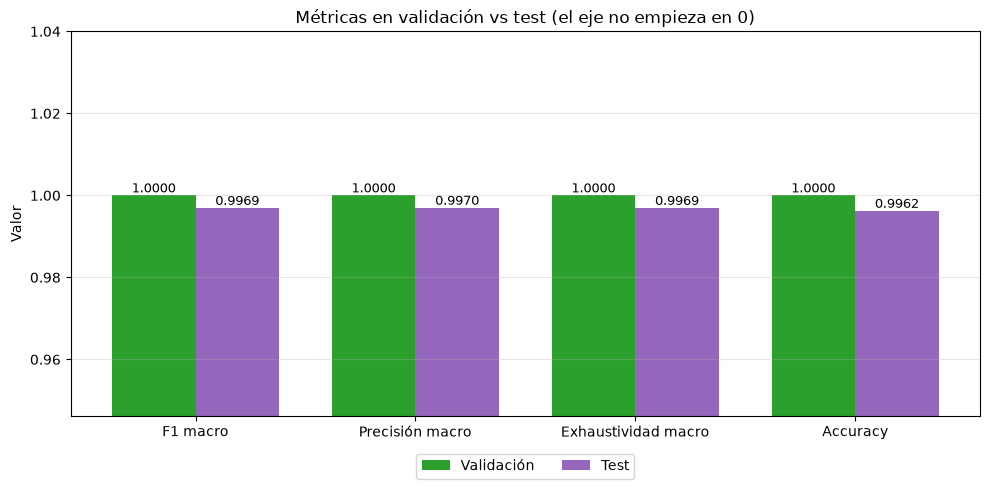

In [14]:
def obtener_probs(loader):
    model.eval()
    probs, reales = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            salida = model(inputs.to(device))
            probs.append(torch.softmax(salida, dim=1).cpu().numpy())
            reales.extend(labels.numpy())
    return np.concatenate(probs), np.array(reales).astype(int)

val_probs, val_reales = obtener_probs(val_loader)
test_probs, test_reales = obtener_probs(test_loader)
val_pred = val_probs.argmax(axis=1)
test_pred = test_probs.argmax(axis=1)

def calcular_metricas(y, p):
    return [f1_score(y, p, average="macro"),
            precision_score(y, p, average="macro", zero_division=0),
            recall_score(y, p, average="macro", zero_division=0),
            accuracy_score(y, p)]

nombres_metricas = ["F1 macro", "Precisión macro", "Exhaustividad macro", "Accuracy"]
m_val = calcular_metricas(val_reales, val_pred)
m_test = calcular_metricas(test_reales, test_pred)

x = np.arange(len(nombres_metricas))
ancho = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - ancho / 2, m_val, ancho, label="Validación", color="tab:green")
b2 = ax.bar(x + ancho / 2, m_test, ancho, label="Test", color="tab:purple")
for barras in (b1, b2):
    for barra in barras:
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                f"{barra.get_height():.4f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(nombres_metricas)
ax.set_ylim(max(0, min(m_val + m_test) - 0.05), 1.04)
ax.set_ylabel("Valor")
ax.set_title("Métricas en validación vs test (el eje no empieza en 0)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("metricas_val_vs_test_palos.png", dpi=300, bbox_inches="tight")
plt.show()

F1 por clase en test. Permite ver qué palo le cuesta más al modelo, algo que el F1 macro promedia y esconde.

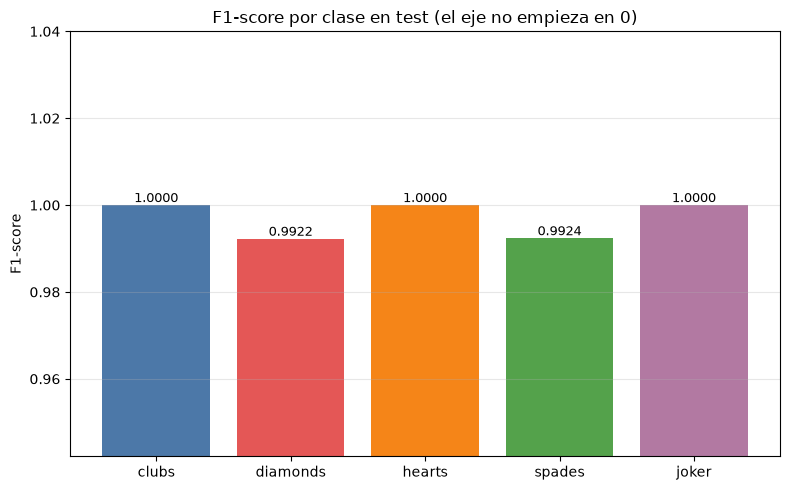

In [15]:
f1_por_clase = f1_score(test_reales, test_pred, average=None, labels=range(NUM_CLASSES), zero_division=0)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(CLASES, f1_por_clase, color=[PALETA[c] for c in CLASES])
for barra, v in zip(barras, f1_por_clase):
    ax.text(barra.get_x() + barra.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(max(0, f1_por_clase.min() - 0.05), 1.04)
ax.set_ylabel("F1-score")
ax.set_title("F1-score por clase en test (el eje no empieza en 0)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("f1_por_clase_palos.png", dpi=300)
plt.show()

Histograma de la confianza del modelo en test, es decir, la probabilidad máxima del softmax, separando aciertos y errores. Lo ideal es que los aciertos se concentren cerca de 1 y los errores, si los hay, queden en la zona media. El eje y está en escala logarítmica para que se vean las barras pequeñas. Tréboles, corazones y comodín tienen 1,0. Diamonds (0,9922) y spades (0,9924) bajan solo por ese único error. Con un solo fallo no podemos decir qué clase es más difícil, y el comodín se evalúa con solo 5 imágenes.

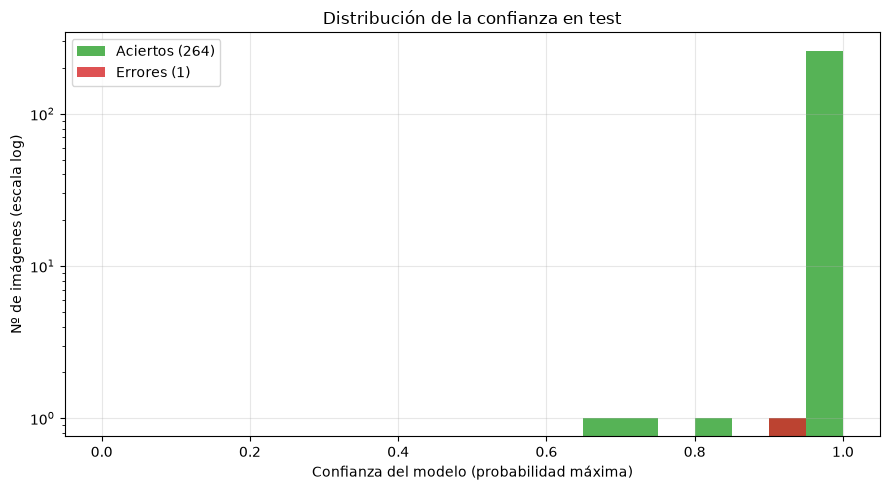

In [16]:
confianza = test_probs.max(axis=1)
acierta = test_pred == test_reales

fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(0, 1, 21)
ax.hist(confianza[acierta], bins=bins, alpha=0.8, color="tab:green", label=f"Aciertos ({acierta.sum()})")
ax.hist(confianza[~acierta], bins=bins, alpha=0.8, color="tab:red", label=f"Errores ({(~acierta).sum()})")
ax.set_yscale("log")
ax.set_xlabel("Confianza del modelo (probabilidad máxima)")
ax.set_ylabel("Nº de imágenes (escala log)")
ax.set_title("Distribución de la confianza en test")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("distribucion_confianza_palos.png", dpi=300)
plt.show()

Las 8 imágenes de test en las que el modelo está menos seguro, medido como la menor diferencia entre la probabilidad de la clase más probable y la de la segunda. Se muestran en vez de solo los errores para que la gráfica no salga vacía si el modelo no falla ninguna. En verde los aciertos y en rojo los fallos. Casi todos los aciertos superan 0,95. El único error tiene confianza 0,909, es decir, el modelo se equivoca con seguridad y un umbral de confianza no lo detectaría.

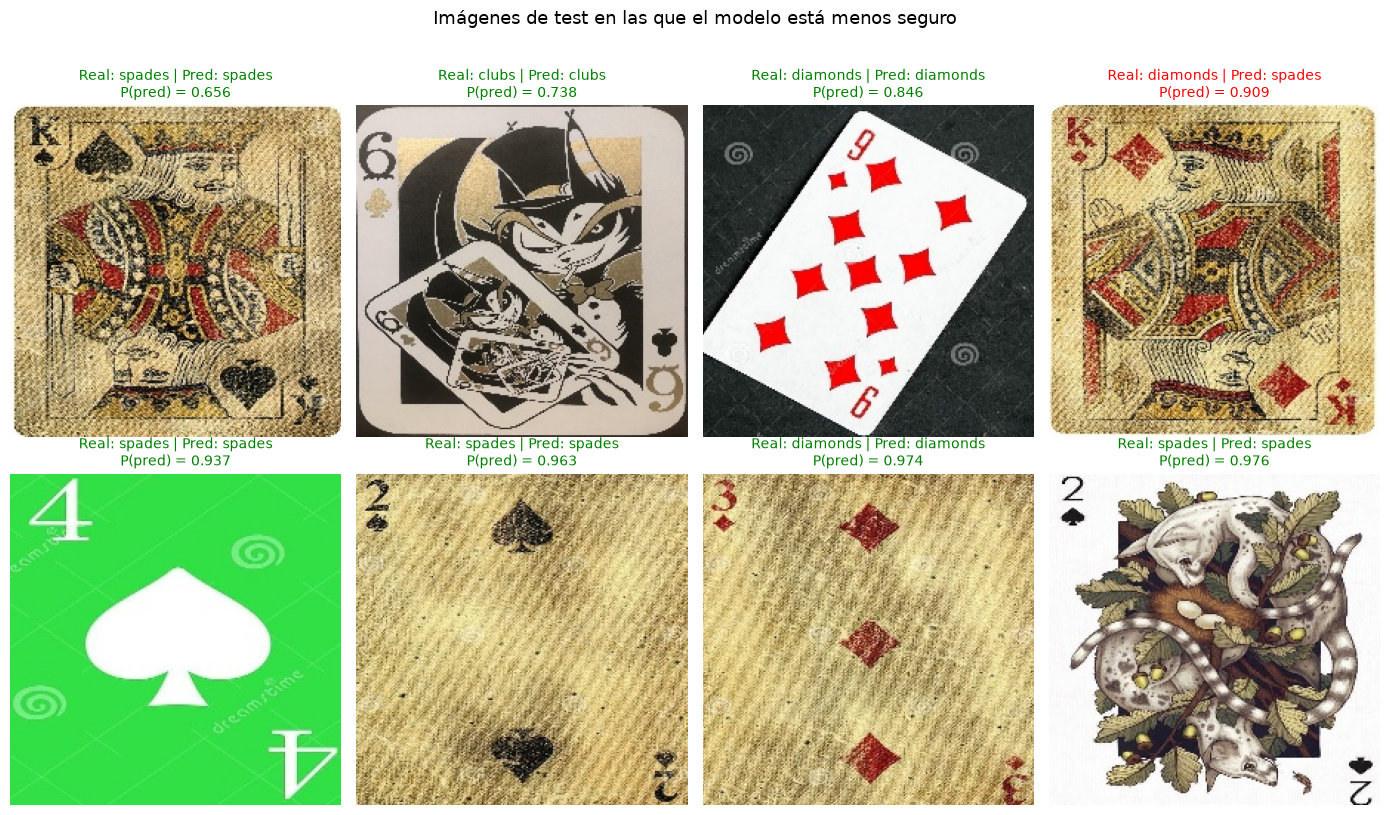

In [17]:
top2 = np.sort(test_probs, axis=1)[:, -2:]
margen = top2[:, 1] - top2[:, 0]
orden = np.argsort(margen)[:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 8.5))
for ax, idx in zip(axes.flat, orden):
    ax.imshow(cv2.cvtColor(X_test[idx], cv2.COLOR_BGR2RGB))
    real = CLASES[test_reales[idx]]
    pred = CLASES[test_pred[idx]]
    ax.set_title(f"Real: {real} | Pred: {pred}\nP(pred) = {test_probs[idx].max():.3f}",
                 color="green" if real == pred else "red", fontsize=10)
    ax.axis("off")
plt.suptitle("Imágenes de test en las que el modelo está menos seguro", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("imagenes_dudosas_palos.png", dpi=300)
plt.show()

Son sobre todo barajas antiguas con fondo texturizado, ilustraciones artísticas y cartas giradas. El único fallo es un rey de diamantes de una baraja antigua. Interpretamos que el problema son los diseños poco habituales, aunque con un solo error no podemos comprobarlo. El 4 de picas con el símbolo blanco sobre fondo verde se clasifica bien, lo que indica que la red no depende solo del color.

## Fuentes

El esqueleto del cuaderno reutiliza el de la parte binaria de esta misma práctica, adaptado a clasificación multiclase.